In [1]:
# SETUP: imports and plot style
import json
import re
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401  (registers the "science" and "ieee" styles)
from matplotlib.patches import Patch
from matplotlib.ticker import AutoMinorLocator, MaxNLocator, MultipleLocator

plt.style.use(["science", "ieee"])

# The figures were designed for 7.5 pt text; everything is scaled up to 10.5 pt
base_font_old = 7.5
base_font = 10.5
legend_font = 9.7
scale_factor = base_font / base_font_old

mpl.rcParams.update({
    # Fonts (LaTeX, Times)
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": base_font,
    "axes.labelsize": base_font,
    "xtick.labelsize": base_font,
    "ytick.labelsize": base_font,
    "legend.fontsize": legend_font,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    # White background, black text and axes, no grid
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.grid": False,
    # Inward major and minor ticks on all four sides
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "xtick.bottom": True,
    "ytick.left": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
})

In [2]:
# LOAD TEA RESULTS
catalyst_folders = {"Ni": "NiMP", "Fe": "FeMP", "AC": "ACMP"}

result_files = {
    "direct_costs":   "Direct_costs_avg.json",
    "fixed_capital":  "Fixed_capital_avg.json",
    "variable_opex":  "Variable_opex_avg.json",
    "fixed_opex":     "Fixed_opex_avg.json",
    "levelized_cost": "LCOH_avg.json",
}

# Project root = first parent folder that contains all catalyst folders
try:
    start_dir = Path(__file__).resolve().parent
except NameError:  # running as a notebook
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in catalyst_folders.values())),
    None,
)
if project_root is None:
    raise FileNotFoundError("Project root not found.")


def load_json(path):
    with open(path, "r") as f:
        return json.load(f)


# results[catalyst][result] -> {component: value}
results = {
    catalyst: {
        result: load_json(project_root / folder / "Results_TEA" / filename)
        for result, filename in result_files.items()
    }
    for catalyst, folder in catalyst_folders.items()
}

In [9]:
# PLOT HELPERS: data preparation, ordering, colors, labels and the stacked-bar plot

# x-axis label of each catalyst's bar (catalyst and operating temperature),
# in plotting order from left to right
bar_labels = {
    "Ni": r"Ni at 600\,$^\circ$C",
    "Fe": r"Fe at 725\,$^\circ$C",
    "AC": r"AC at 825\,$^\circ$C",
}


# ---- Grouping cost components -----------------------------------------------
# Equipment-name pattern -> group in the direct-cost plot (first match wins).
# Compressors, turbines and pumps are grouped as turbomachinery, the reactor
# with the furnace, motors with generators, and coolers with heat exchangers.
# The cyclone is too small to see in the bars and goes into "Other".
direct_cost_groups = [
    (r"^COMP[-_ ]?\d+$",           "Turbomachinery"),
    (r"^MTR[-_ ]?\d+$",            "Motors & generators"),
    (r"^HX[-_ ]?\d+$",             "Heat exchangers"),
    (r"^COOLER[-_ ]?\d+$",         "Heat exchangers"),
    (r"REACTOR|^(CSTR|PFR)$",      "Reactor & furnace"),
    (r"FURNACE",                   "Reactor & furnace"),
    (r"CYCLONE",                   "Other"),
    (r"TURBINE",                   "Turbomachinery"),
    (r"PUMP",                      "Turbomachinery"),
    (r"CO2.*CAPTURE|CAPTURE.*CO2", "CO2-capture"),
    (r"PSA",                       "PSA"),
    (r"GENERATOR",                 "Motors & generators"),
]


def direct_cost_group(name):
    upper = name.upper().strip()
    for pattern, group in direct_cost_groups:
        if re.search(pattern, upper):
            return group
    return name


def fixed_capital_group(name):
    """Unify the different spellings of the fixed-capital components."""
    upper = name.upper().strip()
    compact = re.sub(r"[^A-Z0-9]", "", upper)

    if compact in ("ISBL", "OSBL"):
        return compact
    if compact == "DE" or ("DESIGN" in upper and "ENGINEER" in upper):
        return "Design and Engineering"
    if "CONTINGENCY" in upper:
        return "Contingency"
    if "ADDITIONAL" in upper and "CAPEX" in upper:
        return "Additional CAPEX"
    return name


def regroup(breakdown, group_of):
    """Sum the values of all components that map to the same group."""
    grouped = {}
    for name, value in breakdown.items():
        group = group_of(name)
        grouped[group] = grouped.get(group, 0.0) + float(value)
    return grouped


def collect(result, group_of=None, divisor=1.0):
    """Return {bar label: {component: value / divisor}} for one TEA result."""
    data = {}
    for catalyst, label in bar_labels.items():
        breakdown = results[catalyst][result]
        if group_of is not None:
            breakdown = regroup(breakdown, group_of)
        data[label] = {name: float(value) / divisor for name, value in breakdown.items()}
    return data


# ---- Component ordering and colors ------------------------------------------
def components_in(data):
    """All components, in order of first appearance."""
    components = []
    for breakdown in data.values():
        for component in breakdown:
            if component not in components:
                components.append(component)
    return components


def order_by_total(data):
    """Components sorted by their summed |value| over all bars, largest first."""
    def total(component):
        return sum(abs(float(b.get(component, 0.0))) for b in data.values())
    return sorted(components_in(data), key=total, reverse=True)


def legend_order_by_bar(data, catalyst):
    """Components of one catalyst's bar from largest to smallest, then the
    components that only appear in other bars, by total size."""
    bar = data[bar_labels[catalyst]]
    lead = sorted(bar, key=lambda c: abs(float(bar[c])), reverse=True)
    return lead + [c for c in order_by_total(data) if c not in lead]


other_color = "#D3D2CD"  # light neutral gray, reserved for the "Other" group


def to_oklab(rgb):
    """sRGB (0-1) -> OKLab, a color space where distance matches how
    different two colors look."""
    r, g, b = [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in rgb]
    l, m, s = np.cbrt([
        0.4122214708 * r + 0.5363325363 * g + 0.0514459929 * b,
        0.2119034982 * r + 0.6806995451 * g + 0.1073969566 * b,
        0.0883024619 * r + 0.2817188376 * g + 0.6299787005 * b,
    ])
    return np.array([
        0.2104542553 * l + 0.7936177850 * m - 0.0040720468 * s,
        1.9779984951 * l - 2.4285922050 * m + 0.4505937099 * s,
        0.0259040371 * l + 0.7827717662 * m - 0.8086757660 * s,
    ])


def pastel_colors(n, cmap=plt.cm.plasma, span=(0.0, 1.0), lighten=0.25):
    """n colors along a colormap (same plasma scale as the deactivation plot),
    mixed with white by `lighten` for a pastel look.

    The colors are spaced so that every step looks equally different (equal
    OKLab distance), instead of equally spaced along the colormap: plasma
    changes slowly through the purples, which made those colors look alike.
    """
    def pastel(x):
        r, g, b, _ = cmap(x)
        return tuple(c + (1.0 - c) * lighten for c in (r, g, b))

    # Cumulative perceived distance along the (pastel) colormap
    xs = np.linspace(*span, 1001)
    lab = np.array([to_oklab(pastel(x)) for x in xs])
    distance = np.concatenate([[0.0], np.cumsum(np.linalg.norm(np.diff(lab, axis=0), axis=1))])

    # Positions that split that distance into n - 1 equal steps
    positions = np.interp(np.linspace(0.0, distance[-1], n), distance, xs)
    return [pastel(x) for x in positions]


def colors_along_scale(components, palette=None):
    """Assign colors to the components in the given order (the first gets the
    first color); "Other" always gets the neutral gray. Without a palette, the
    components are spread over the pastel plasma scale."""
    named = [c for c in components if c != "Other"]
    if palette is None:
        palette = pastel_colors(len(named))
    colors = {c: palette[i % len(palette)] for i, c in enumerate(named)}
    if "Other" in components:
        colors["Other"] = other_color
    return colors


def complete_color_map(data, preferred_colors=None):
    """Use the preferred colors; components without one get a tab20 color."""
    color_map = dict(preferred_colors or {})
    palette = plt.cm.tab20.colors
    missing = [c for c in components_in(data) if c not in color_map]
    for i, component in enumerate(missing):
        color_map[component] = palette[i % len(palette)]
    return color_map


# ---- Legend labels ----------------------------------------------------------
label_replacements = {
    "electricity":            "Electricity",
    "methane_feed":           "Methane feed",
    "catalyst_feed":          "Catalyst feed",
    "cooling_water":          "Cooling water",
    "CO2_tax":                r"CO$_2$ tax",
    "CO2 tax":                r"CO$_2$ tax",
    "carbon_disposal_fee":    "Carbon disposal fee",
    "catalyst_separation":    "Catalyst separation",
    "CO2-capture":            r"CO$_2$ capture",
    "D&E":                    "Design and Engineering",
    r"D\&E":                  "Design and Engineering",
    "Design & Engineering":   "Design and Engineering",
    r"Design \& Engineering": "Design and Engineering",
    "R&D":                    r"R\&D",
    "Motors & generators":    r"Motors \& generators",
    "Reactor & furnace":      r"Reactor \& furnace",
    "Side revenue":           "Carbon revenue",  # LCOH: revenue from selling the carbon
    r"R\&D":                  r"R\&D",
}


def clean_label(name):
    label = label_replacements.get(name, name)
    if r"\&" in label:  # keep labels with an escaped (LaTeX) ampersand as they are
        return label
    label = label.replace(r"\&", " and ").replace("&", " and ")
    return re.sub(r"\s+", " ", label).strip()


# ---- Stacked-bar plot -------------------------------------------------------
def plot_stacked_bars(
    data,
    ylabel,
    preferred_colors=None,
    legend_order=None,
    y_max=None,
    y_major_step=None,
    y_minor_step=None,
    shift_by_negative=False,
    legend_loc=None,
    legend_fontsize=legend_font,
    legend_ncol=1,
    legend_first_column=None,
    ylabel_fontsize=None,
    y_multiplier=None,
    hatches=None,
    ax=None,
):
    """One stacked bar per catalyst.

    Positive components stack upward from 0 (largest at the bottom); negative
    components (e.g. carbon sales) stack downward from 0. With
    `shift_by_negative`, the positive stack starts at the bottom of the
    negative stack, so the top of the bar shows the net value.
    `y_multiplier` (e.g. r"$\times 10^{6}$") is written above the top of
    the y-axis, like matplotlib's scientific-notation offset.
    `legend_loc` places the legend inside the plot (e.g. "upper left");
    by default it goes outside, to the right. `hatches` maps components to
    a hatch pattern (e.g. {"Side revenue": "///"}). Pass `ax` to draw into
    an existing subplot (e.g. one panel of a combined figure).
    """
    color_map = complete_color_map(data, preferred_colors)
    if legend_order is None:
        legend_order = components_in(data)
    hatches = hatches or {}

    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(4 * scale_factor, 2.8 * scale_factor))
    else:
        fig = ax.figure
    bar_style = dict(width=0.62, edgecolor="black", linewidth=0.8)

    max_positive = 0.0
    min_negative = 0.0

    for x, breakdown in enumerate(data.values()):
        values = [(c, float(v)) for c, v in breakdown.items()]
        positive = sorted([cv for cv in values if cv[1] >= 0], key=lambda cv: cv[1], reverse=True)
        negative = sorted([cv for cv in values if cv[1] < 0], key=lambda cv: abs(cv[1]), reverse=True)

        bottom = sum(v for _, v in negative) if shift_by_negative else 0.0
        for component, value in positive:
            ax.bar(x, value, bottom=bottom, color=color_map[component],
                   hatch=hatches.get(component), zorder=2, **bar_style)
            bottom += value
        max_positive = max(max_positive, bottom)

        bottom = 0.0
        for component, value in negative:
            ax.bar(x, value, bottom=bottom, color=color_map[component],
                   hatch=hatches.get(component), zorder=3, **bar_style)
            bottom += value
        min_negative = min(min_negative, bottom)

    # x-axis: one tick per catalyst
    ax.set_xticks(np.arange(len(data)))
    ax.set_xticklabels(data.keys(), fontsize=base_font)
    ax.set_xlim(-0.65, len(data) - 0.35)

    # y-axis: headroom above the bars, and a zero line if anything is negative
    ax.set_ylabel(ylabel, fontsize=ylabel_fontsize or base_font, labelpad=7)
    if y_max is None:
        y_max = max_positive * 1.08
    if min_negative < 0:
        ax.set_ylim(min_negative * 1.15, y_max)
        ax.axhline(0, color="black", linewidth=1.0, zorder=5)
    else:
        ax.set_ylim(0, y_max)

    ax.yaxis.set_major_locator(
        MultipleLocator(y_major_step) if y_major_step is not None else MaxNLocator(nbins=7))
    ax.yaxis.set_minor_locator(
        MultipleLocator(y_minor_step) if y_minor_step is not None else AutoMinorLocator(5))

    ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)
    ax.tick_params(axis="both", which="major", length=4.9, width=1.1, pad=7, labelsize=base_font)
    ax.tick_params(axis="both", which="minor", length=2.8, width=0.8)

    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.1)

    if y_multiplier is not None:
        ax.text(0.0, 1.01, y_multiplier, transform=ax.transAxes,
                ha="left", va="bottom", fontsize=base_font)

    # Legend
    legend_handles = [
        Patch(facecolor=color_map[c], edgecolor="black", linewidth=0.8,
              hatch=hatches.get(c), label=clean_label(c))
        for c in legend_order
    ]
    if legend_first_column is not None:
        # Two columns with only `legend_first_column` entries in the first one:
        # matplotlib fills columns top to bottom, so pad the first column with
        # invisible entries until both columns have the same number of rows.
        first = legend_handles[:legend_first_column]
        second = legend_handles[legend_first_column:]
        blank = Patch(facecolor="none", edgecolor="none", label="")
        legend_handles = first + [blank] * (len(second) - len(first)) + second
        legend_ncol = 2

    if legend_loc is not None:
        legend_position = dict(loc=legend_loc)
    else:
        legend_position = dict(loc="center left", bbox_to_anchor=(1.02, 0.5))
    ax.legend(handles=legend_handles, frameon=False, fontsize=legend_fontsize, ncol=legend_ncol,
              **legend_position)

    if standalone:
        fig.tight_layout()
    return fig, ax

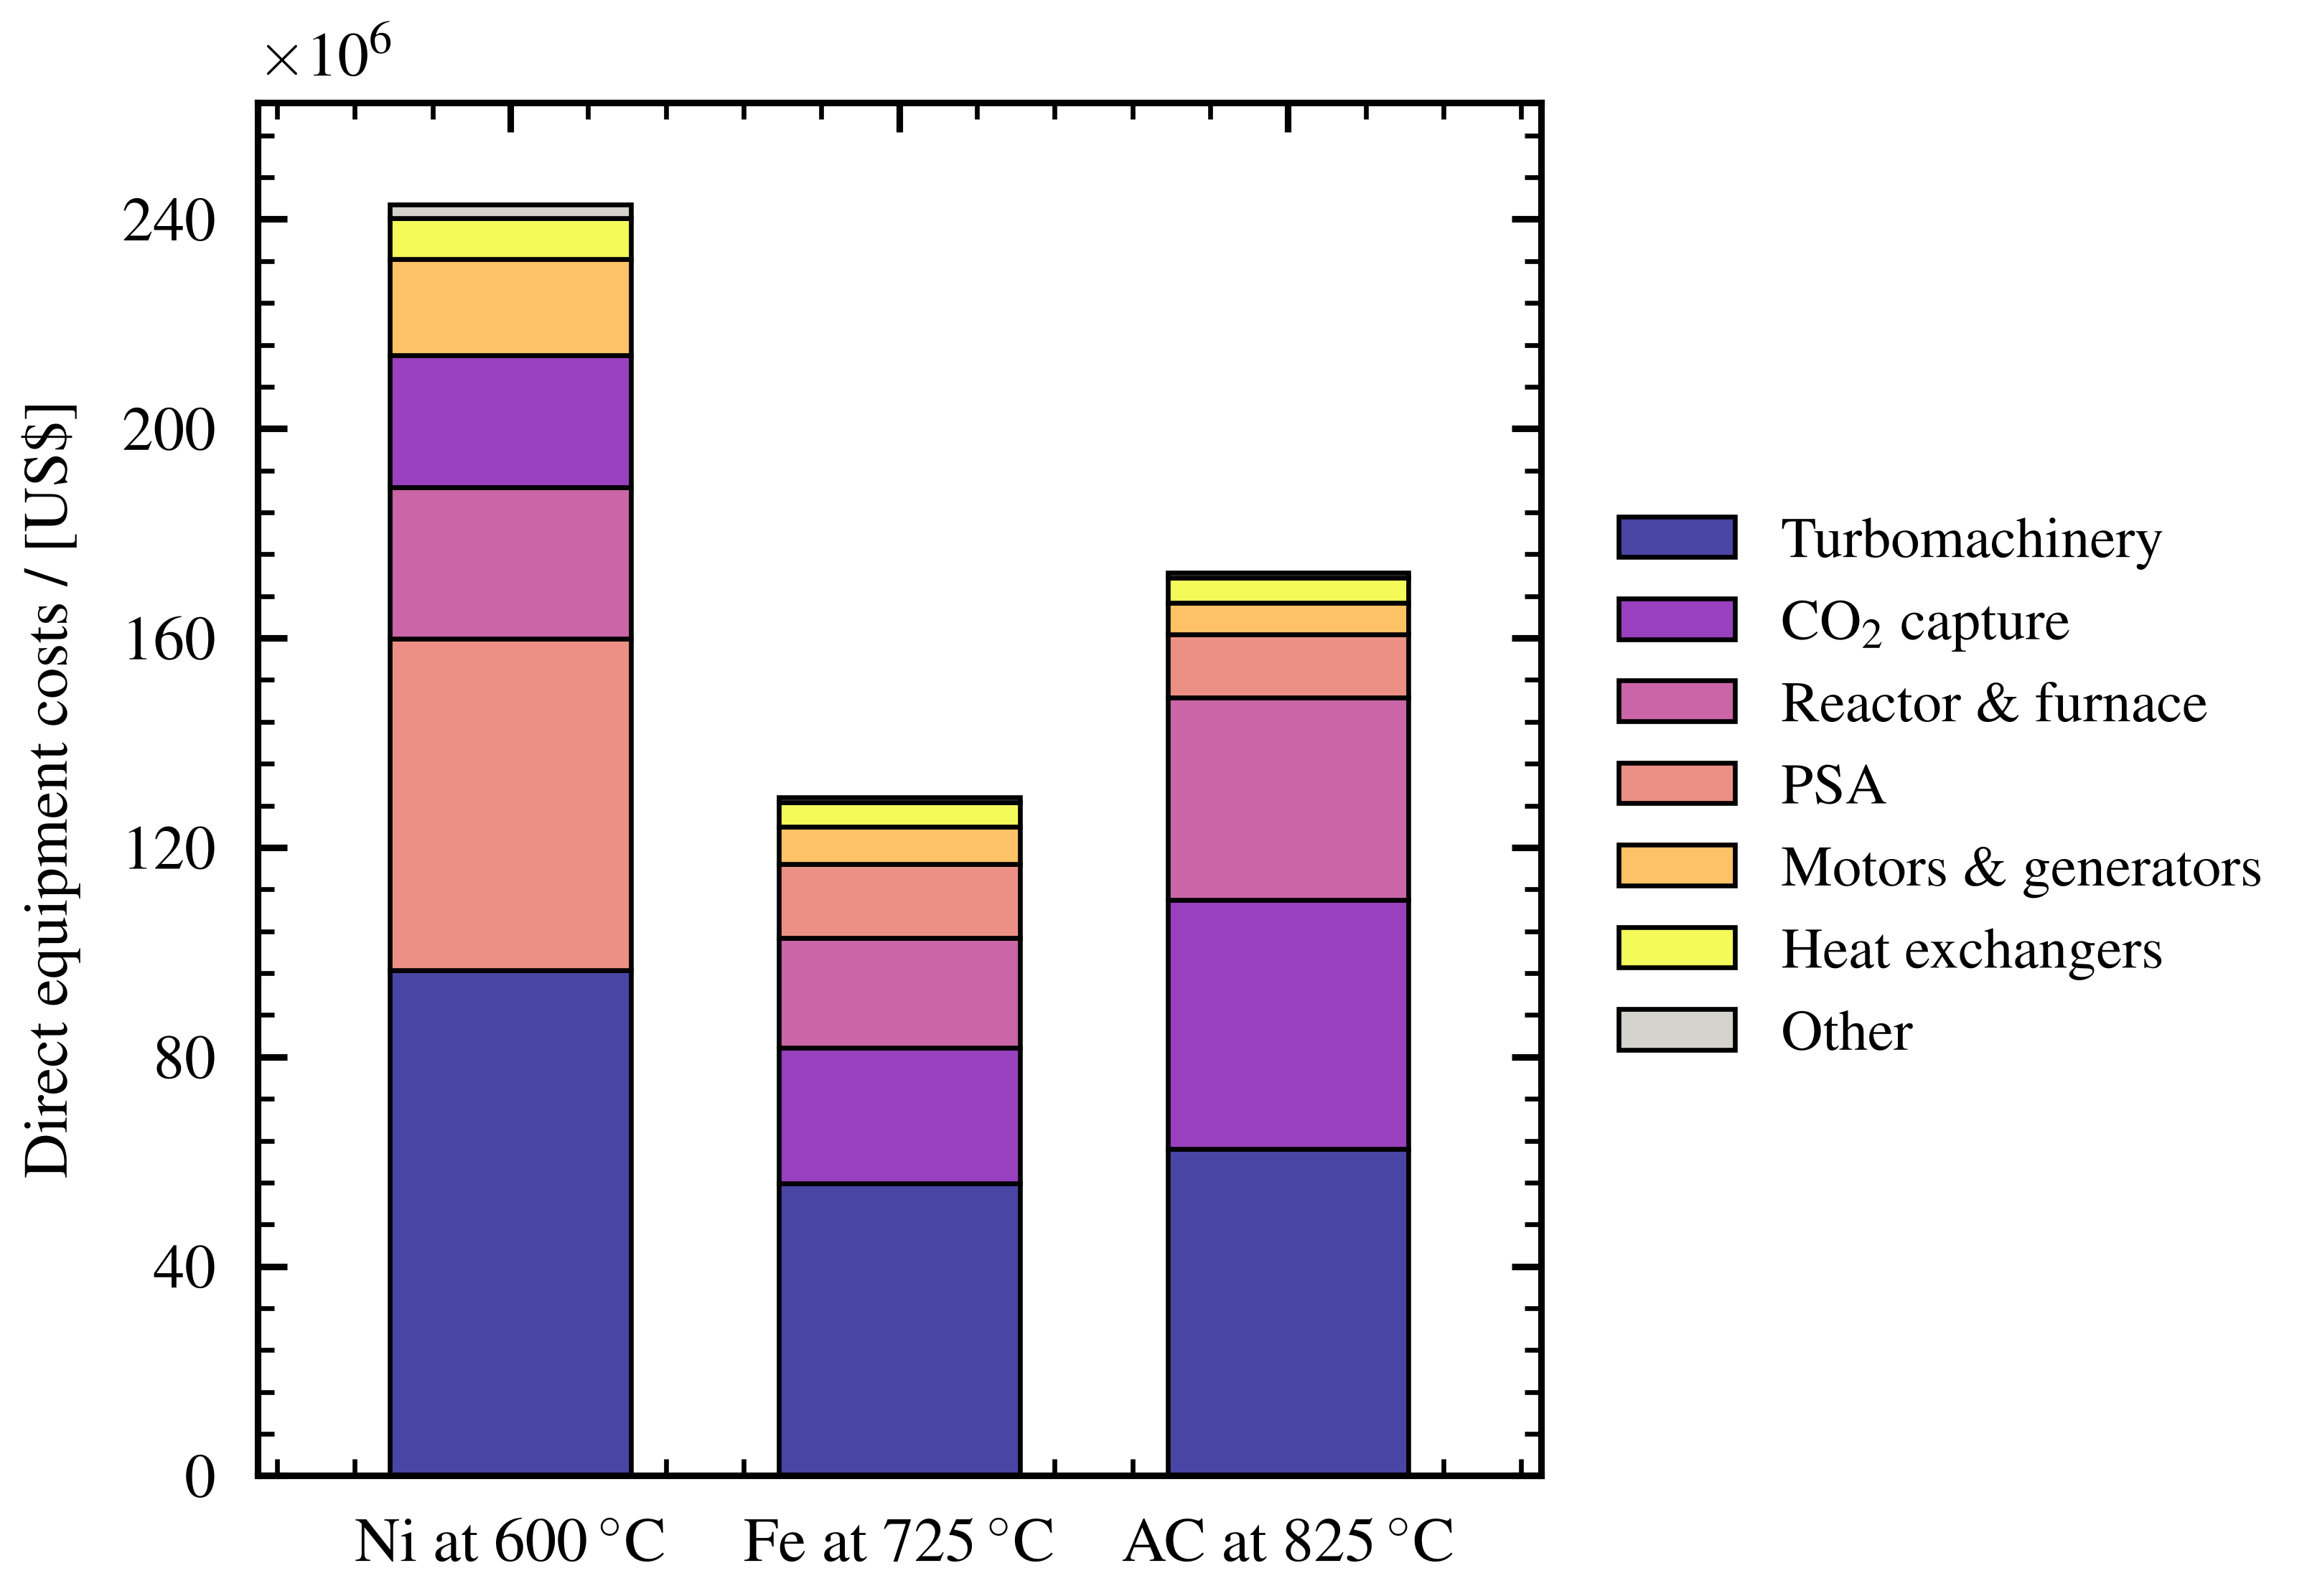

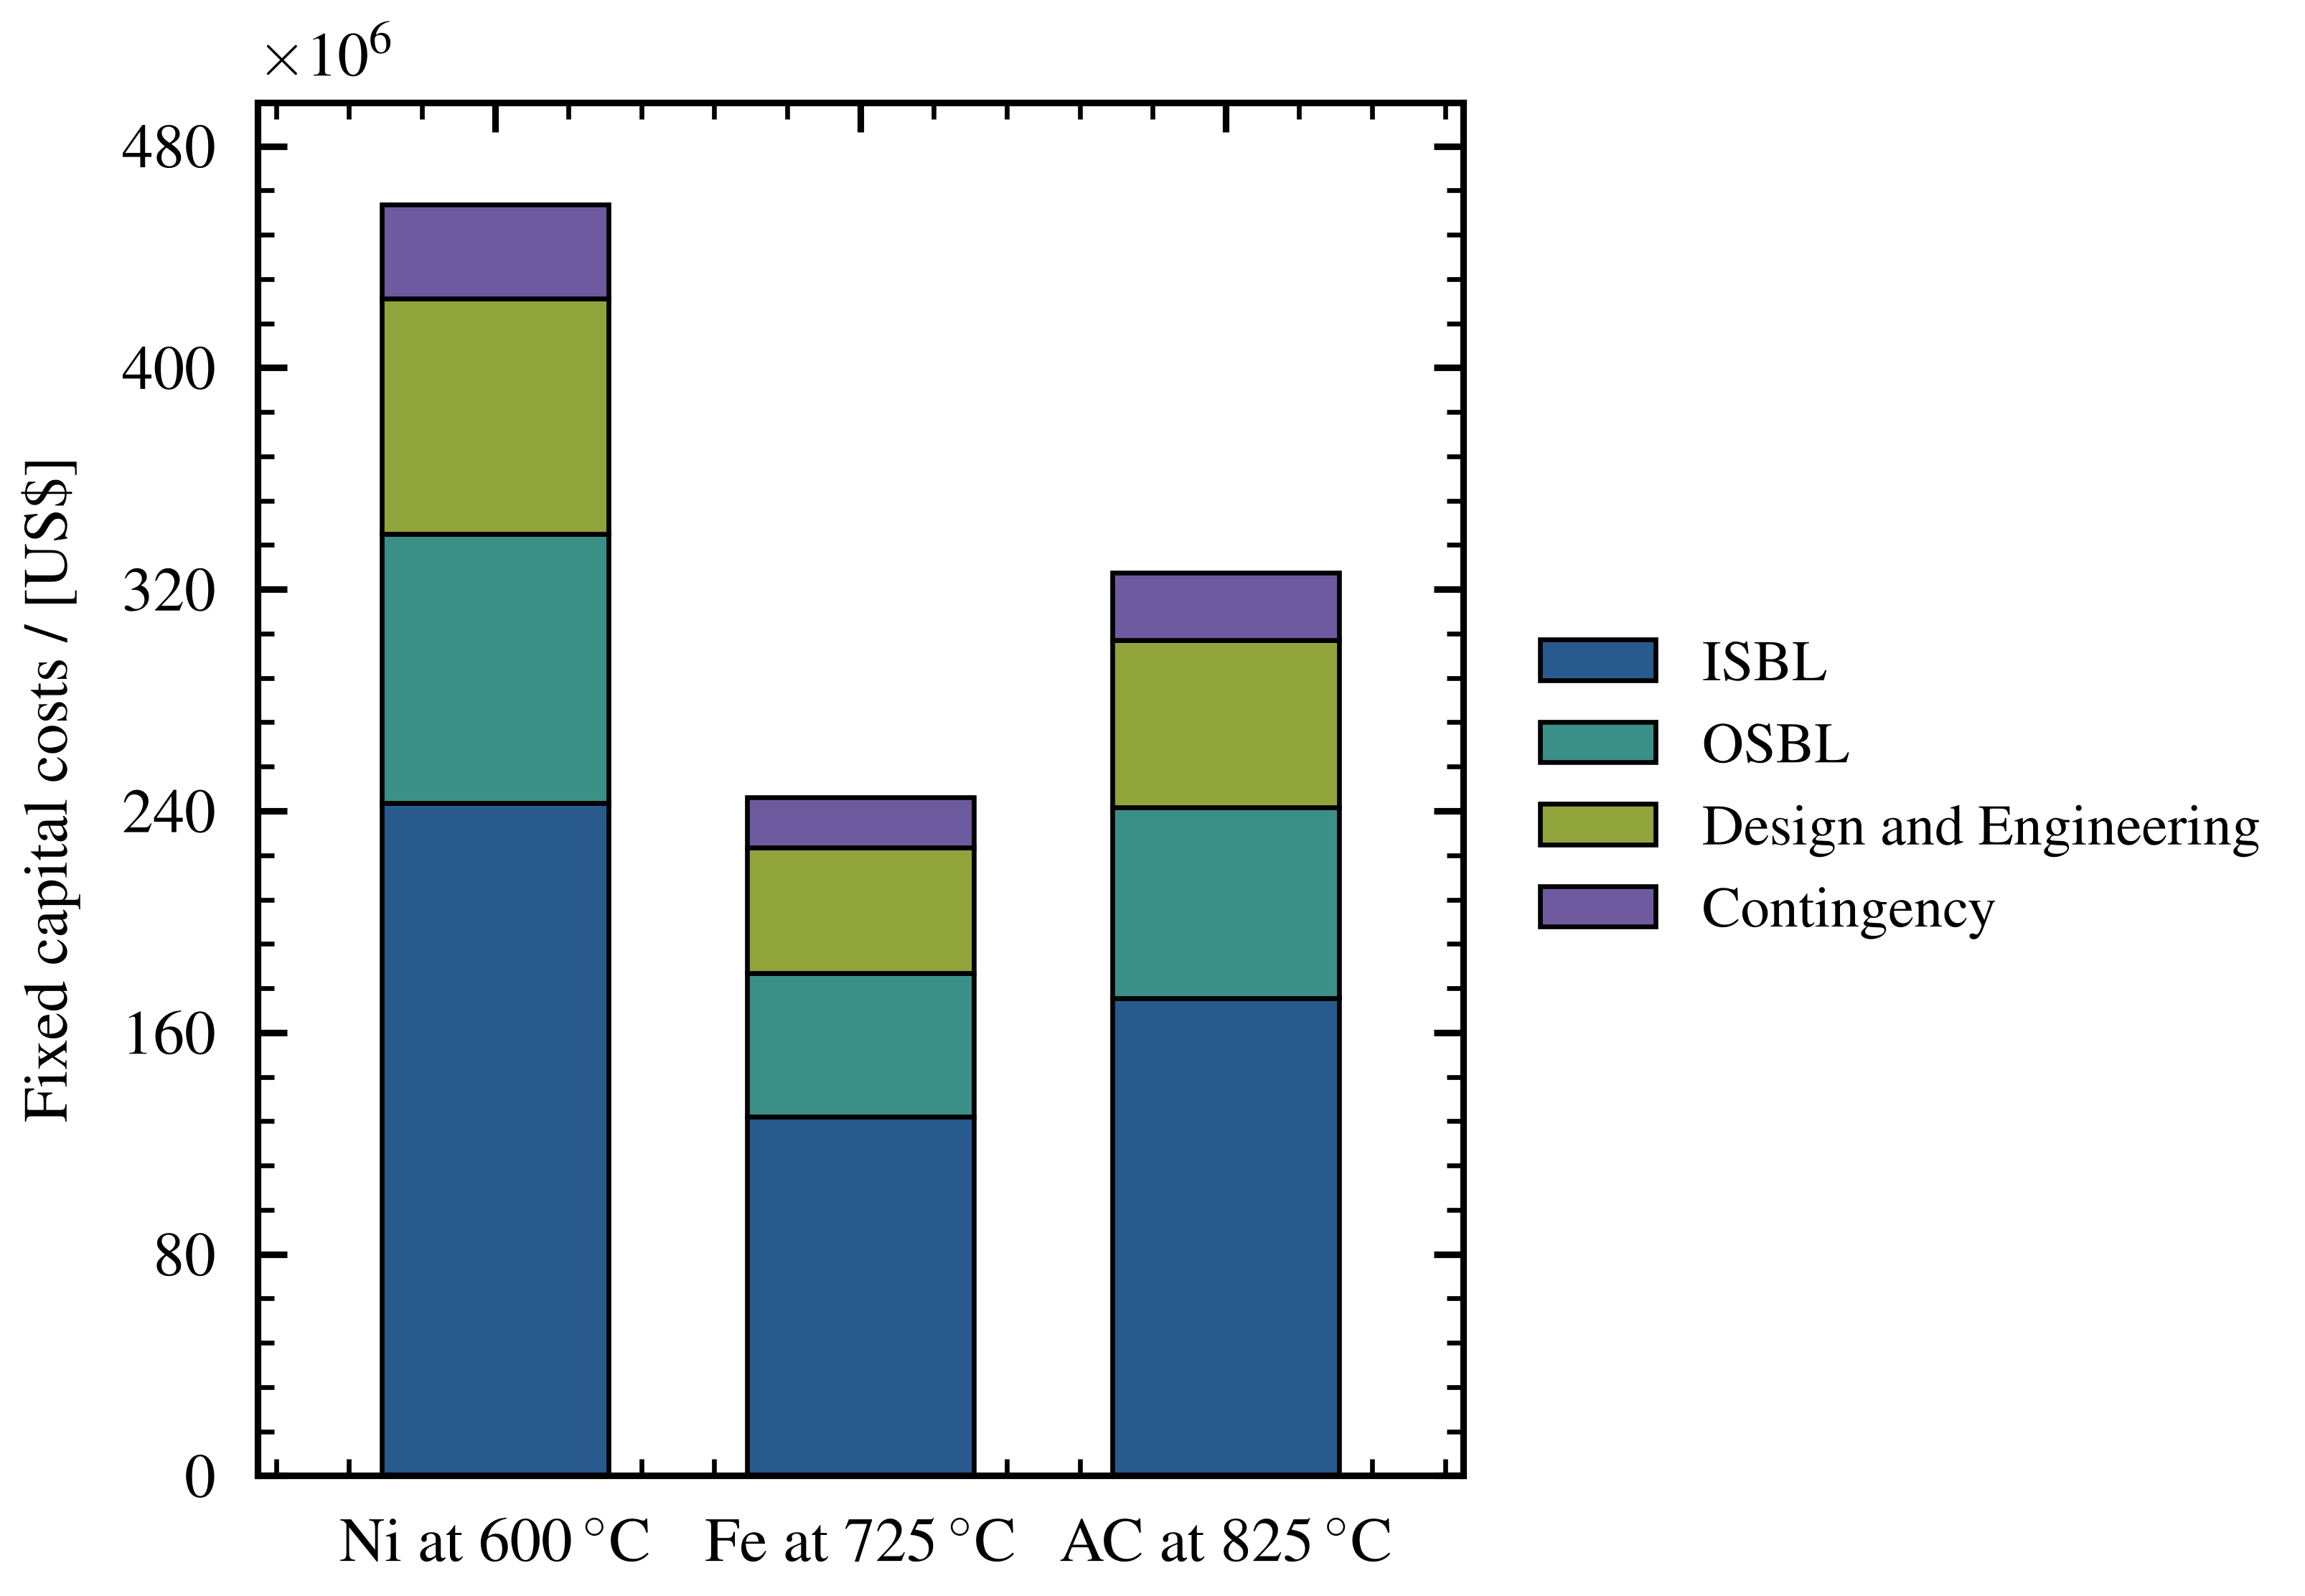

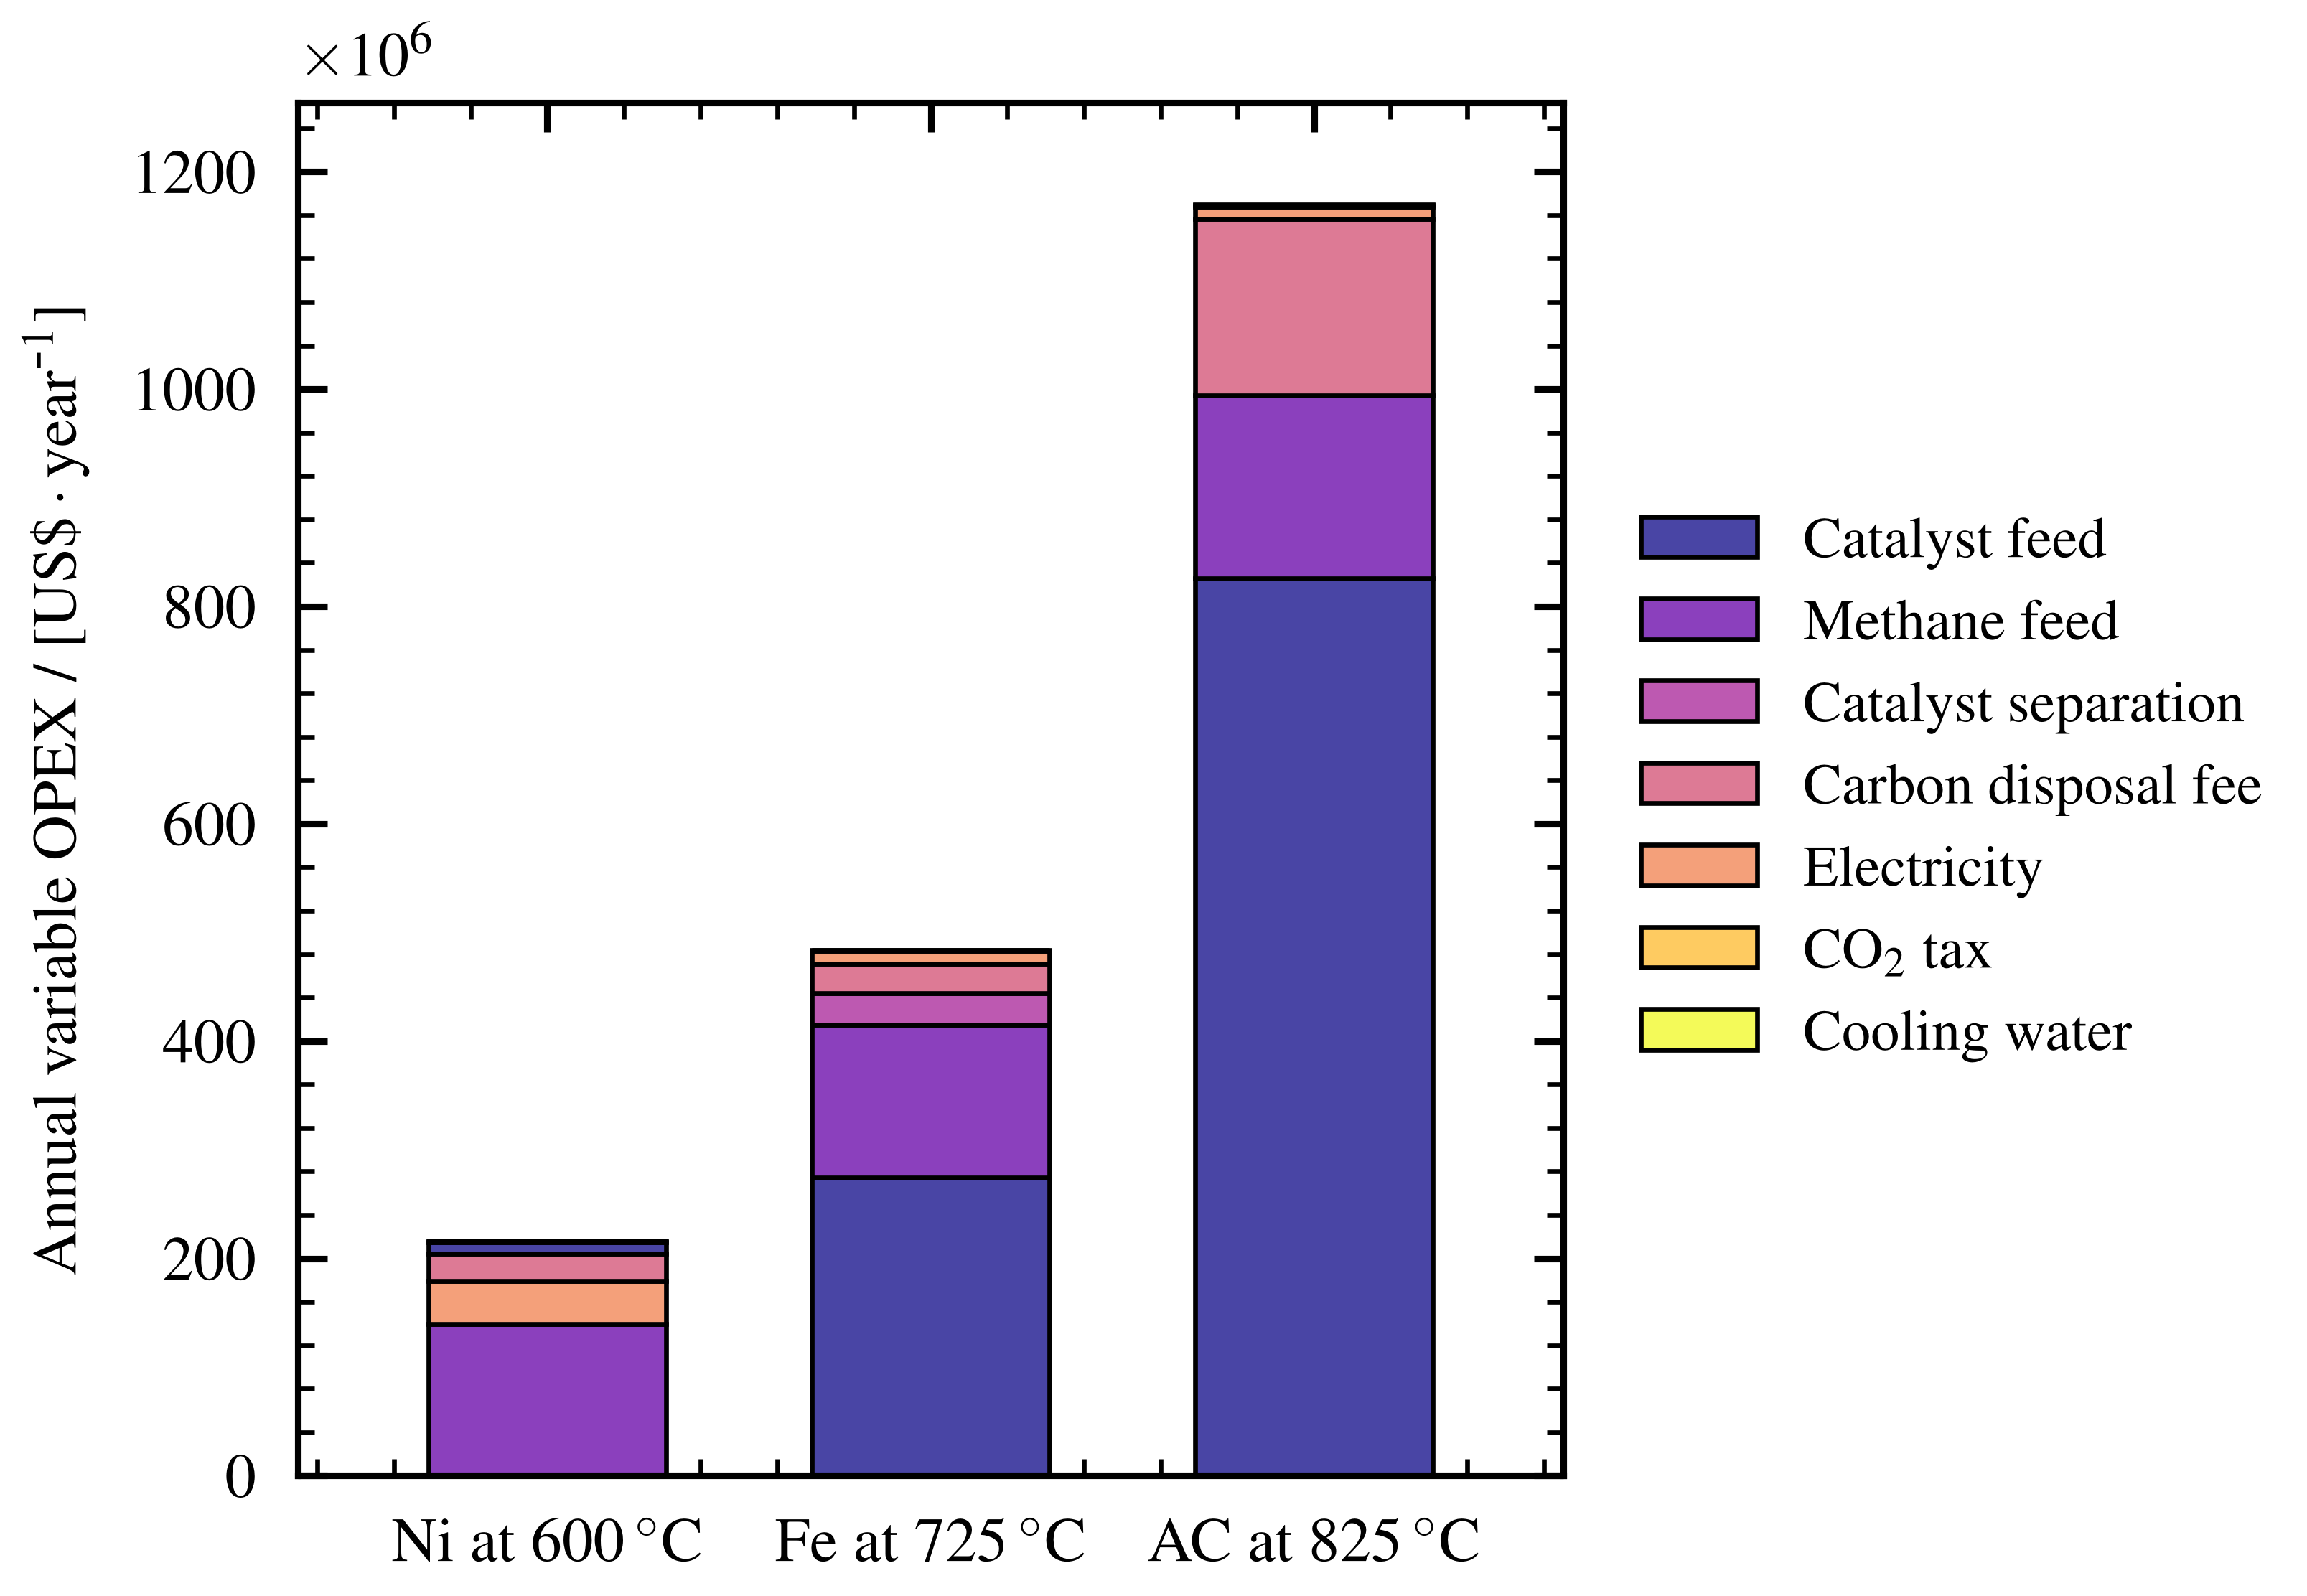

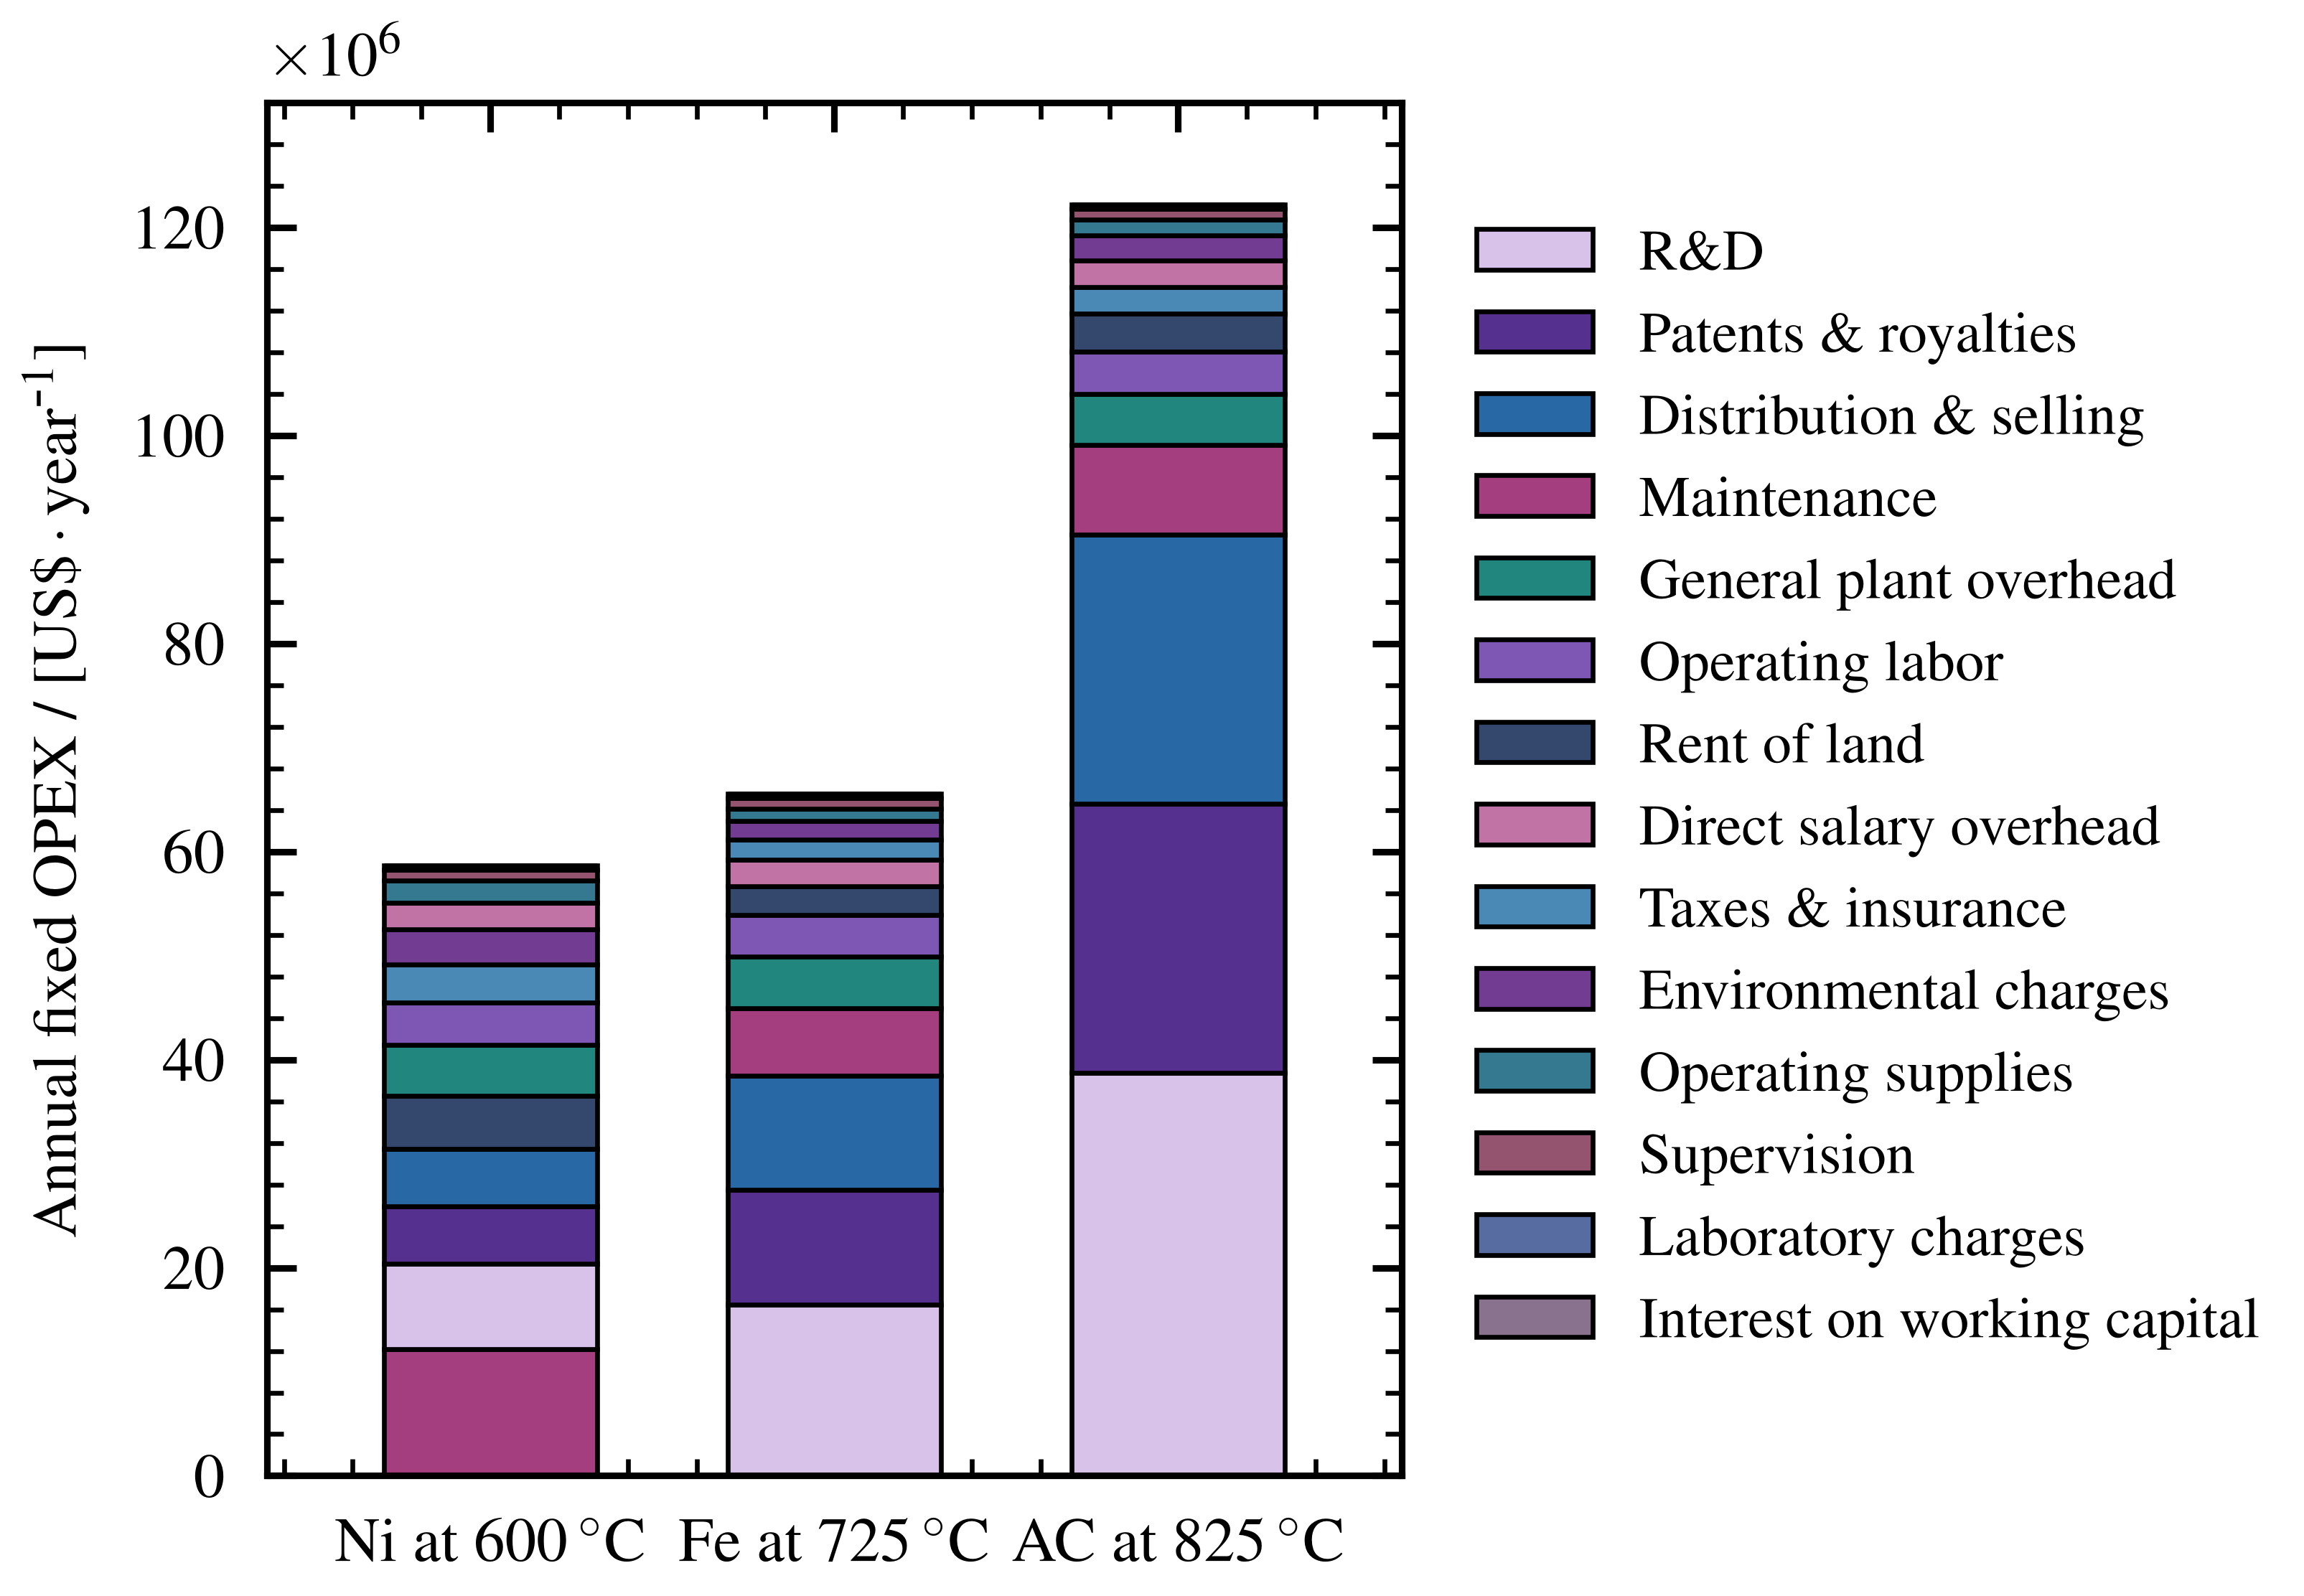

In [10]:
# COST BREAKDOWNS (values in 10^6 US$, shown as x10^6 above the y-axis)
direct_data        = collect("direct_costs", group_of=direct_cost_group, divisor=1e6)
fixed_capital_data = collect("fixed_capital", group_of=fixed_capital_group, divisor=1e6) #SI: FIGURE S.9 - FCI
variable_opex_data = collect("variable_opex", divisor=1e6)
fixed_opex_data    = collect("fixed_opex", divisor=1e6) #SI: FIGURE S.10 - FIXOPEX

# Palettes: colors follow the legend order (largest component of the Fe bar first),
# so the legend reads as one smooth gradient.
# None = pastel plasma scale (deep blue -> purple -> pink -> peach), spread over
# however many components the plot has, in equally large color steps.
direct_palette = None
fixed_capital_palette = ["#285A8E", "#3A8F86", "#91A33B", "#6E5A9E", "#9ABBD0"]
variable_opex_palette = None
fixed_opex_palette = [
    "#D9C2EA", "#55308E", "#2868A4", "#A53E7E", "#21877E", "#7E57B5", "#34476D",
    "#C073A4", "#4A88B6", "#713C91", "#34798F", "#94546F", "#576CA0", "#88728E",
]

per_year = r"\,$\cdot$\,year$^{\mbox{-}1}$"
direct_ylabel = r"Direct equipment costs / [US\$]"
variable_opex_ylabel = r"Annual variable OPEX / [US\$" + per_year + "]"

cost_figures = [
    # (data, palette, y-axis label, output file)
    (direct_data, direct_palette, direct_ylabel, "direct_equipment_costs.pdf"),
    (fixed_capital_data, fixed_capital_palette,
     r"Fixed capital costs / [US\$]", "fixed_capital_costs.pdf"),
    (variable_opex_data, variable_opex_palette, variable_opex_ylabel,
     "annual_variable_opex.pdf"),
    (fixed_opex_data, fixed_opex_palette,
     r"Annual fixed OPEX / [US\$" + per_year + "]", "annual_fixed_opex.pdf"),
]


def cost_plot_options(data, palette):
    """Colors, legend order and x10^6 marker shared by all cost-breakdown plots."""
    legend_order = legend_order_by_bar(data, "Fe")
    return dict(
        preferred_colors=colors_along_scale(legend_order, palette),
        legend_order=legend_order,
        y_multiplier=r"$\times 10^{6}$",
    )


for data, palette, ylabel, filename in cost_figures:
    fig, ax = plot_stacked_bars(data, ylabel, **cost_plot_options(data, palette))
    fig.savefig(filename, format="pdf")

plt.show()

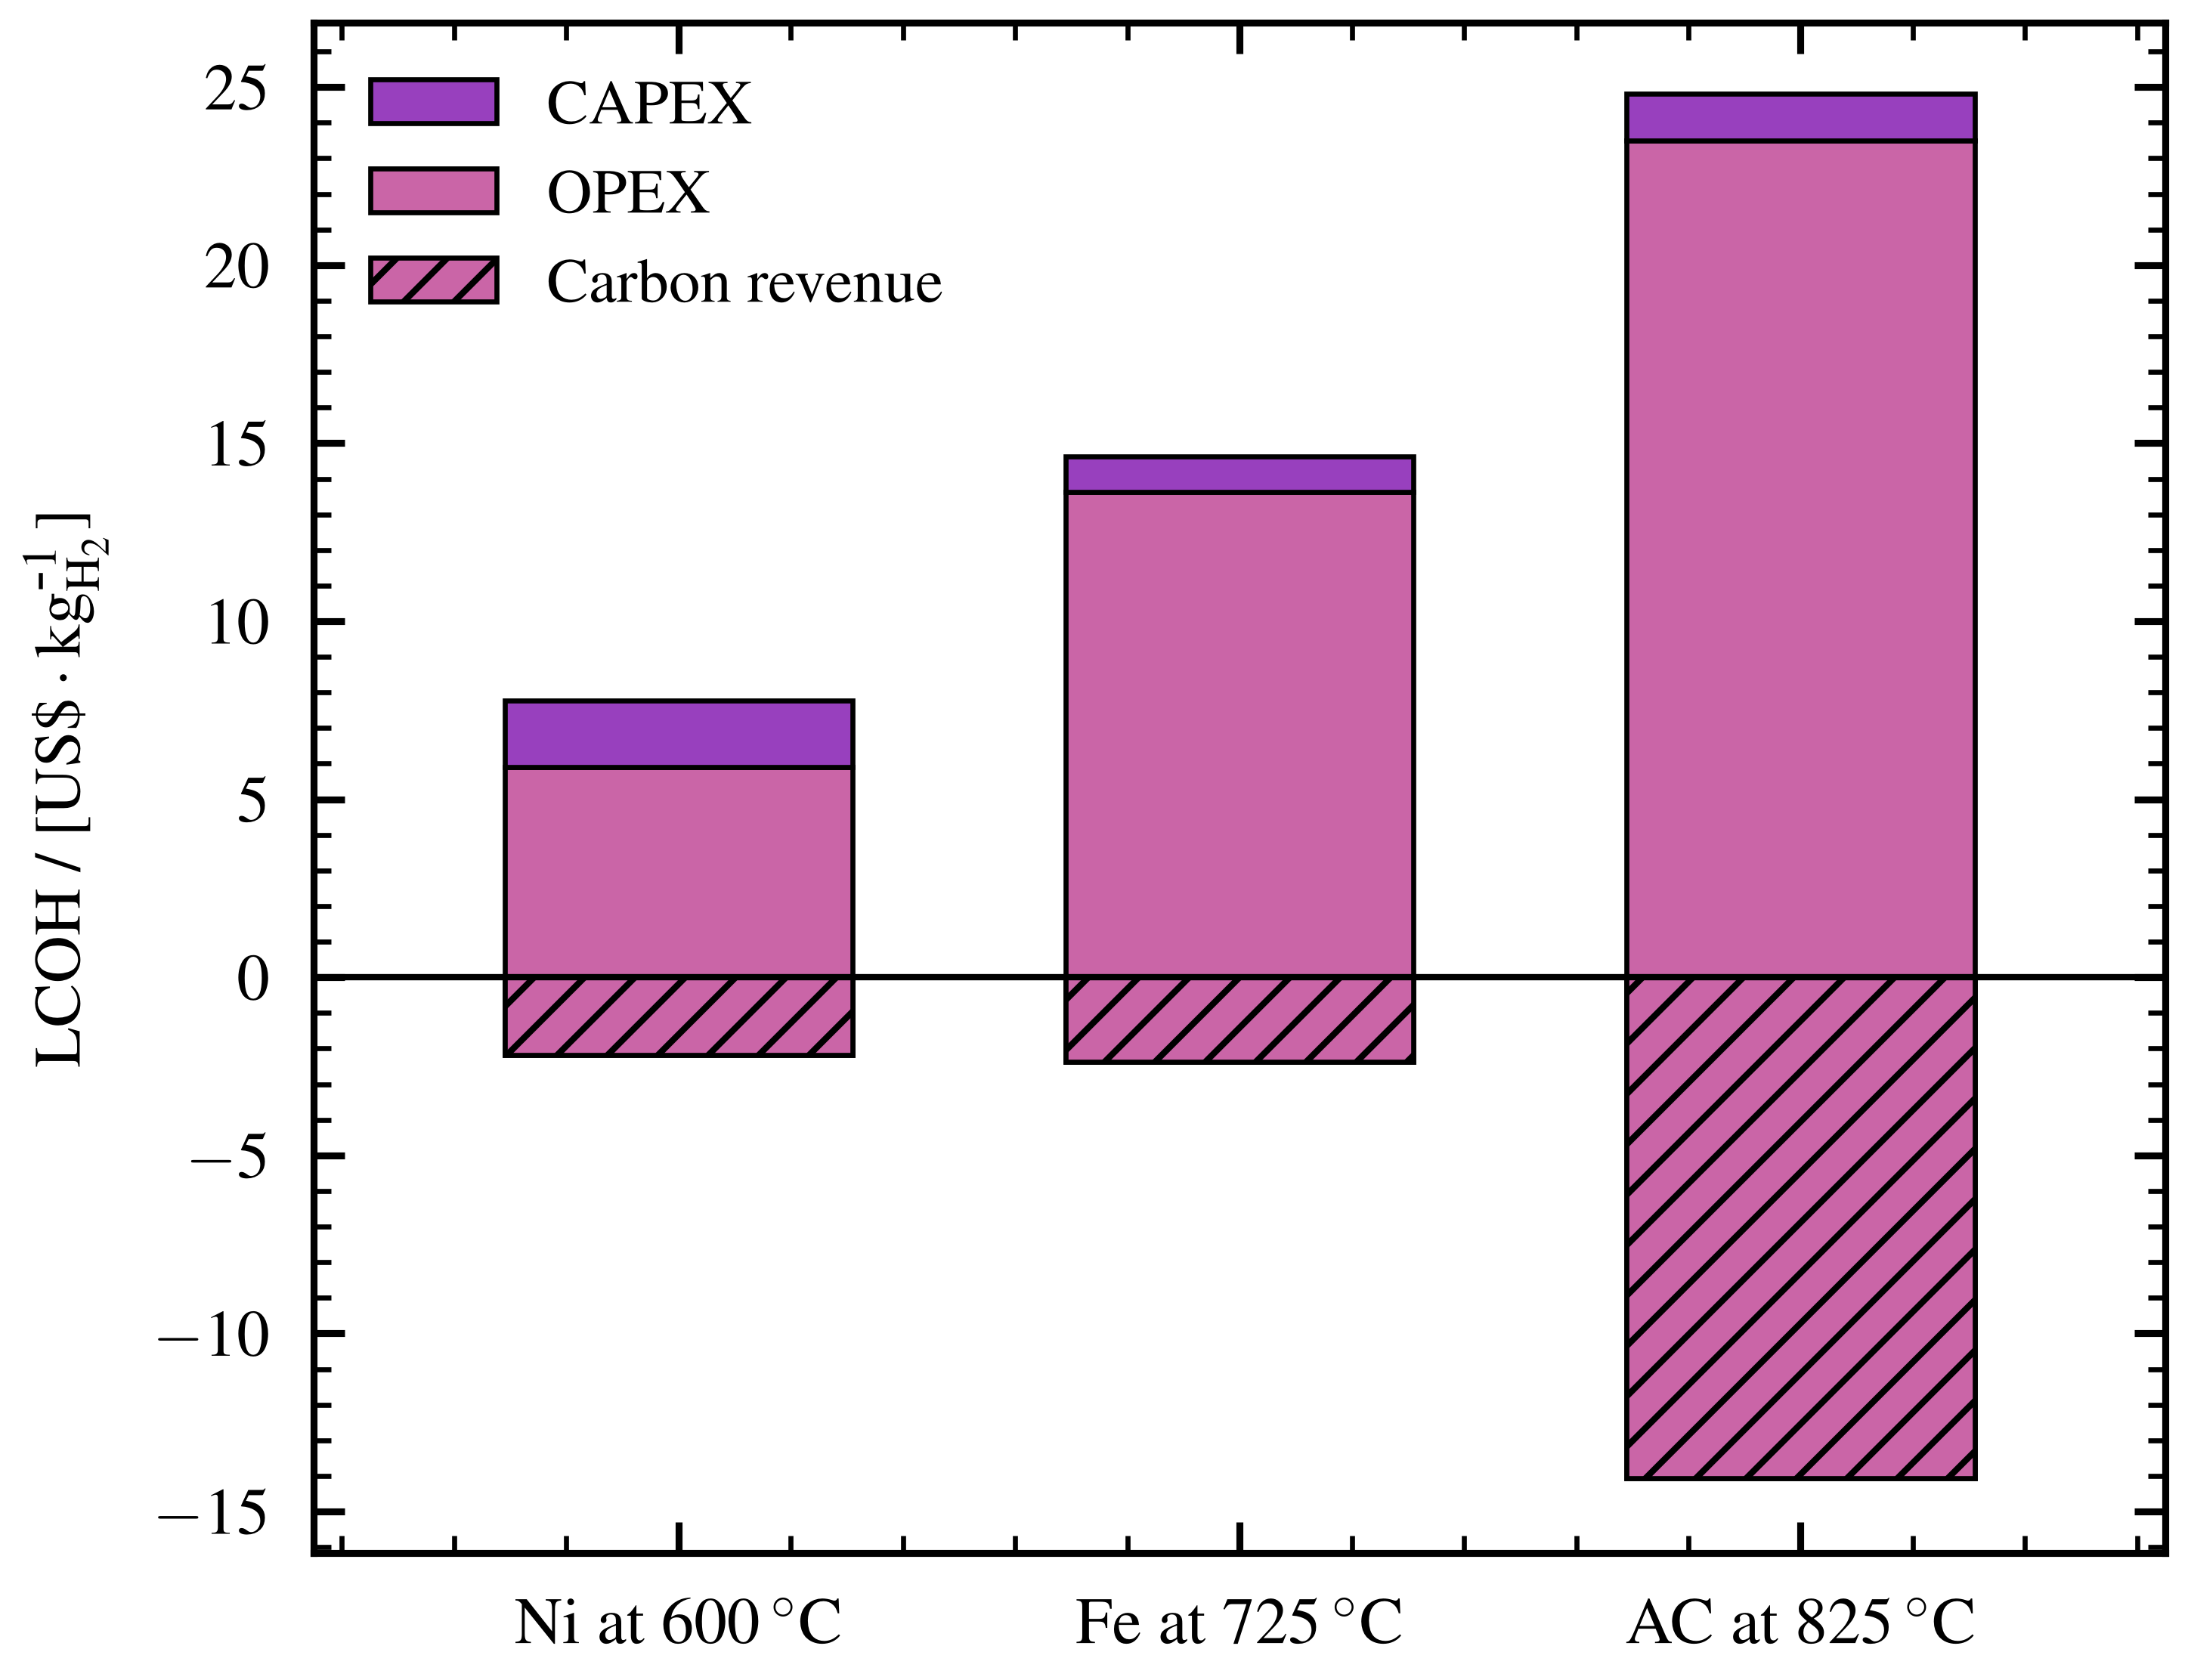

In [5]:
# LCOH BASELINE (US$/kg H2); side revenue (carbon sales) is negative and stacks
# below zero, in the OPEX color with a hatch
levelized_cost_data = collect("levelized_cost")

opex_color = "#CA65A7"  # pink, from the pastel plasma scale
levelized_colors = {
    "CAPEX":        "#9840BE",  # purple, from the pastel plasma scale
    "OPEX":         opex_color,
    "Side revenue": opex_color,
}
levelized_hatches = {"Side revenue": "///"}

lcoh_ylabel = r"LCOH / [US\$\,$\cdot$\,kg$_{\mathrm{H_2}}^{\mbox{-}1}$]"
lcoh_options = dict(
    preferred_colors=levelized_colors,
    hatches=levelized_hatches,
    y_major_step=5,
    y_minor_step=1,
    shift_by_negative=True,
    legend_loc="upper left",
    legend_fontsize=10.0,
)

fig_levelized, ax_levelized = plot_stacked_bars(levelized_cost_data, lcoh_ylabel, **lcoh_options)
fig_levelized.savefig("levelized_cost_breakdown.pdf", format="pdf")

plt.show()

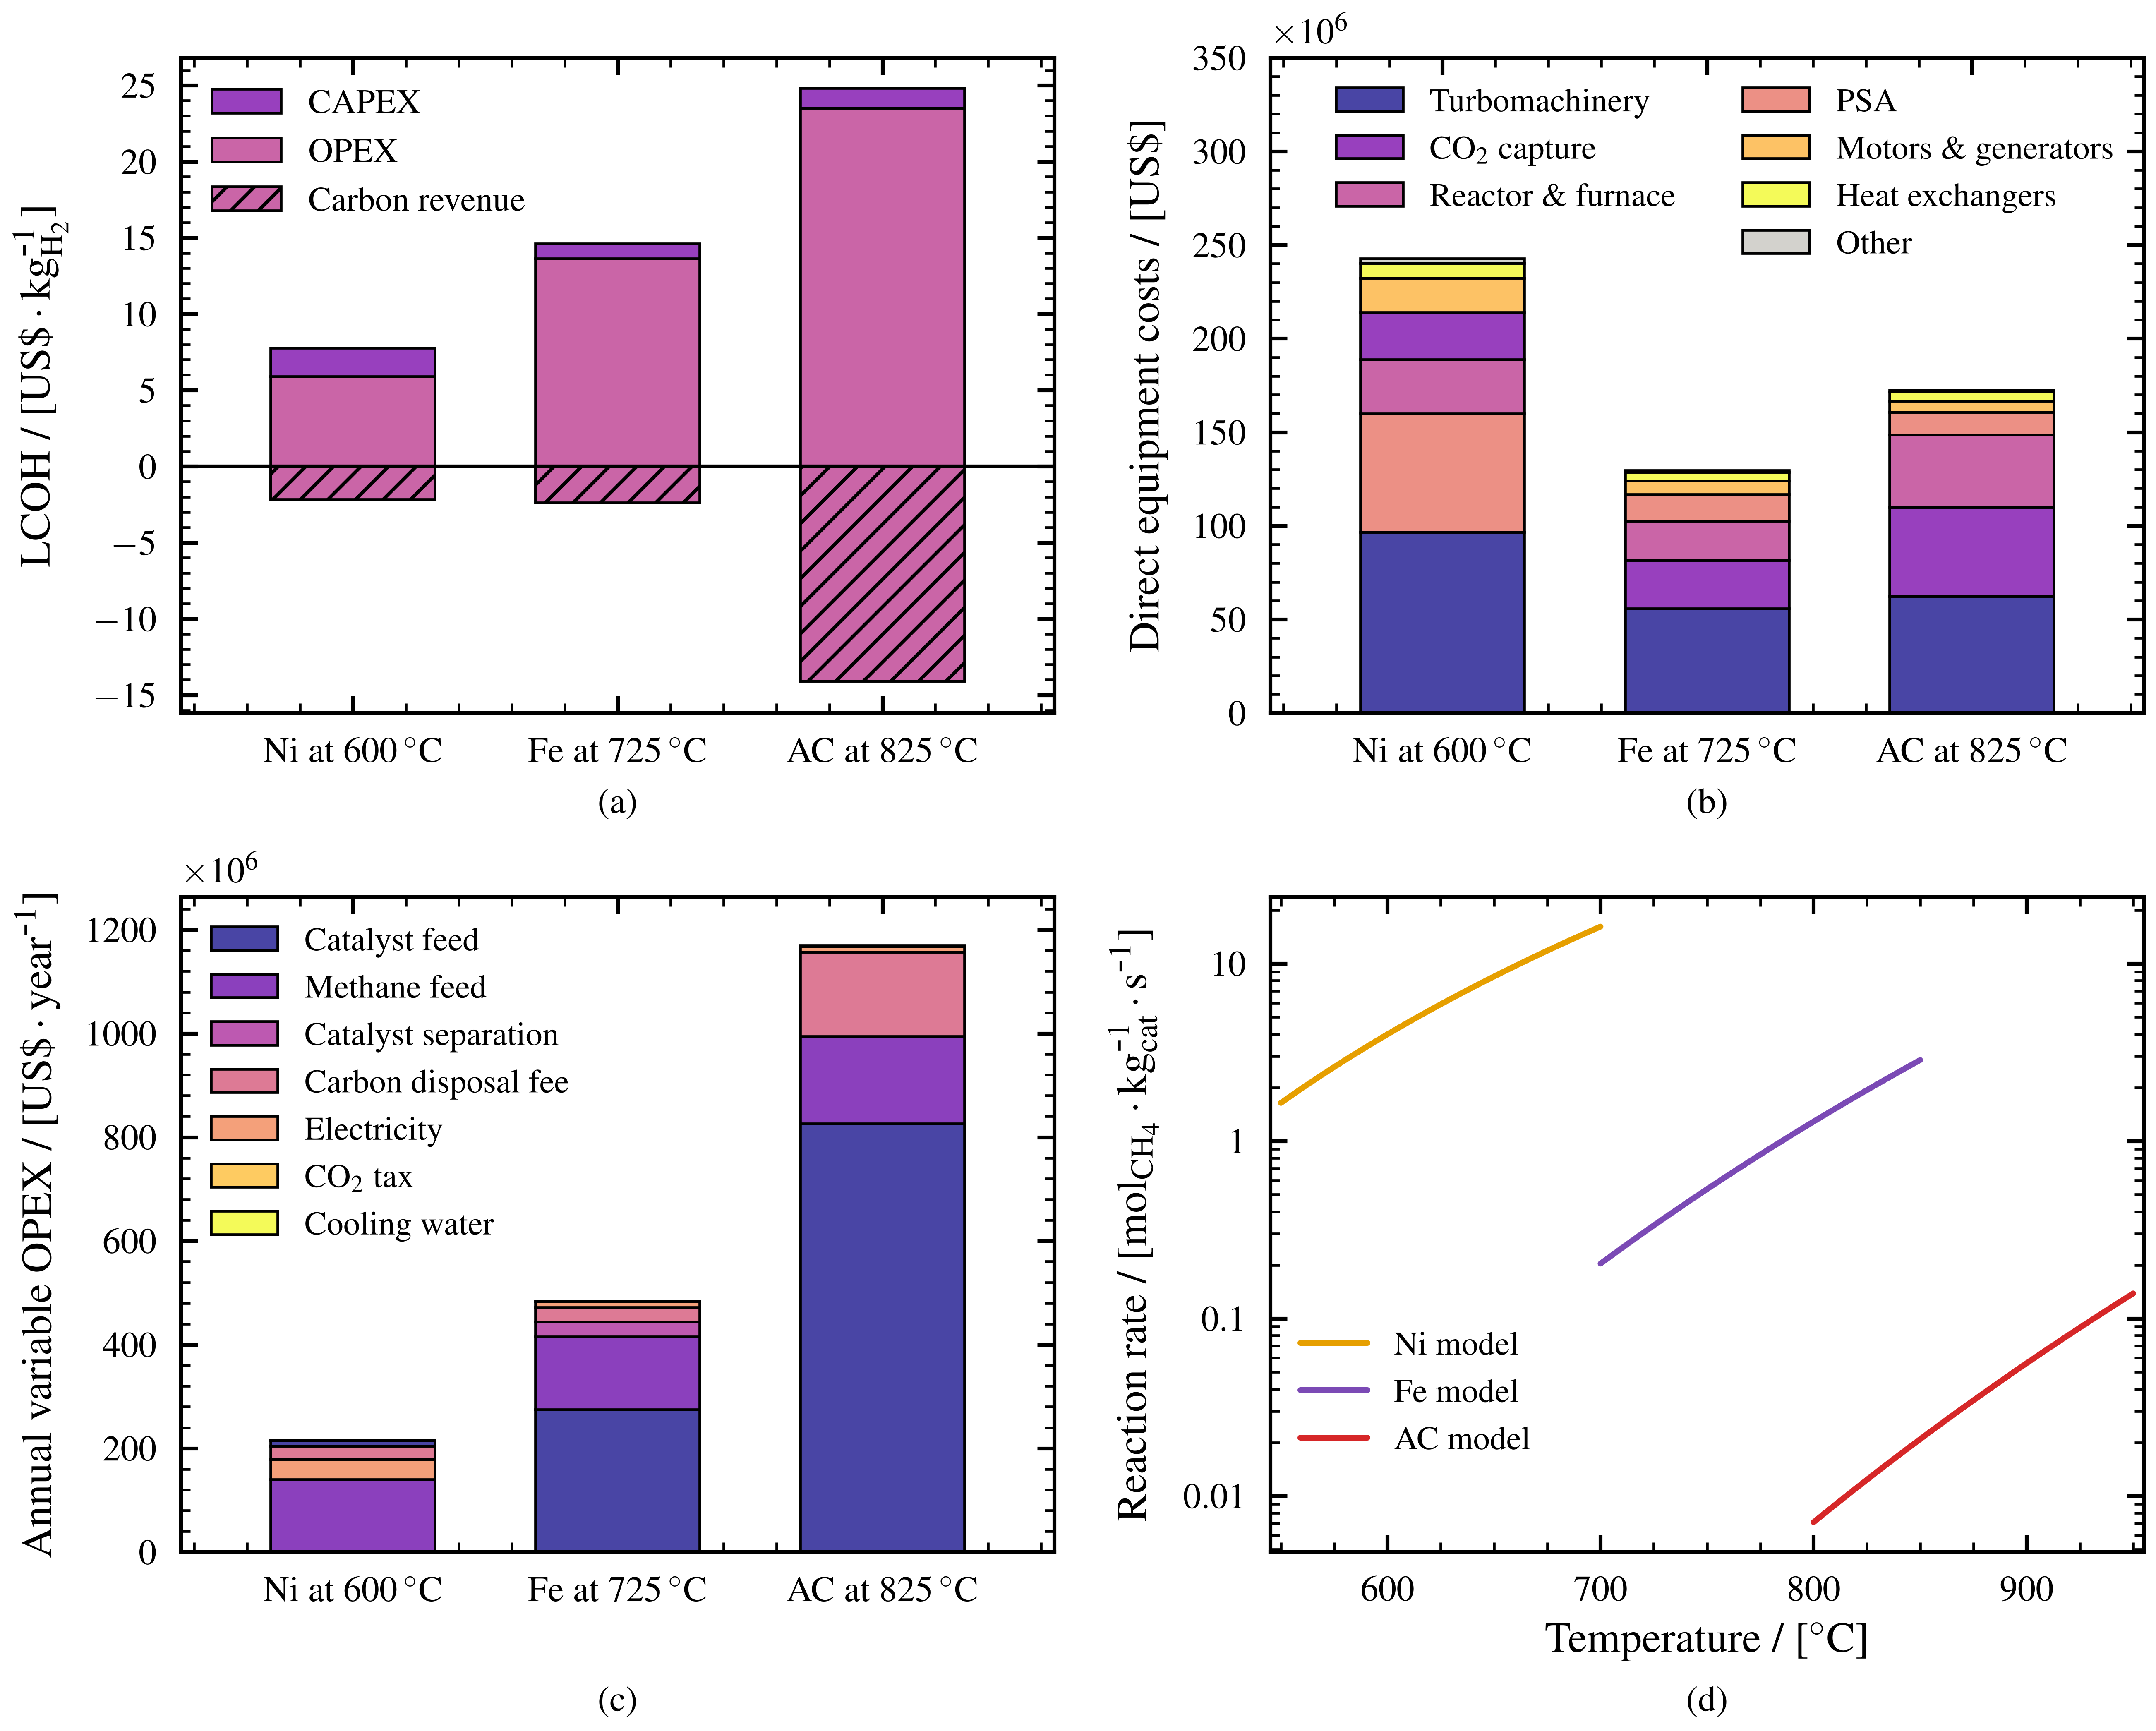

In [6]:
# COMBINED FIGURE (2x2): (a) LCOH, (b) direct equipment costs,
# (c) annual variable OPEX, (d) reaction rate vs. temperature
import importlib
import reaction_kinetics
importlib.reload(reaction_kinetics)  # pick up edits to reaction_kinetics.py without a kernel restart
from reaction_kinetics import draw_reaction_rates, rate_label, temperature_label

# Panels wider than tall (4:3, like the single plots), all legends inside the panels
fig, axes = plt.subplots(2, 2, figsize=(8.8, 7.0), layout="constrained")
# Tight spacing: only the space the labels need between panels, no extra padding
fig.get_layout_engine().set(w_pad=0.06, h_pad=0.06, wspace=0.0, hspace=0.0)
axis_label_size = 12.5  # axis labels a bit larger than the 10.5 pt tick labels
ax_lcoh, ax_direct, ax_opex, ax_rate = axes.flat
for ax in axes.flat:
    ax.set_box_aspect(3 / 4)  # height / width

# (a)-(c): the same plots as above, drawn into the panels
plot_stacked_bars(levelized_cost_data, lcoh_ylabel, ax=ax_lcoh, ylabel_fontsize=axis_label_size,
                  **lcoh_options)
# (b): two-column legend (3 + 4 entries) across the top, with the y-axis raised so it
# clears the bars
plot_stacked_bars(direct_data, direct_ylabel, ax=ax_direct, legend_loc="upper right",
                  ylabel_fontsize=axis_label_size, legend_first_column=3,
                  y_max=350, **cost_plot_options(direct_data, direct_palette))
# (c): legend in the empty space above the Ni and Fe bars
plot_stacked_bars(variable_opex_data, variable_opex_ylabel, ax=ax_opex, legend_loc="upper left",
                  ylabel_fontsize=axis_label_size,
                  **cost_plot_options(variable_opex_data, variable_opex_palette))

# (d): reaction rates (models from reaction_kinetics.py), styled like the bar panels
draw_reaction_rates(ax_rate, linewidth=1.2 * scale_factor)
ax_rate.set_xlabel(temperature_label, fontsize=axis_label_size)
ax_rate.set_ylabel(rate_label, fontsize=axis_label_size, labelpad=7)
ax_rate.tick_params(axis="both", which="both", direction="in", top=True, right=True)
ax_rate.tick_params(axis="both", which="major", length=4.9, width=1.1, pad=7, labelsize=base_font)
ax_rate.tick_params(axis="both", which="minor", length=2.8, width=0.8)
for spine in ax_rate.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.1)
# Lower left, raised just above where the carbon curve starts (800 ﷿﷿﷿﷿﷿﷿C, bottom)
ax_rate.legend(frameon=False, fontsize=legend_font, loc="lower left",
               bbox_to_anchor=(0.0, 0.1))

# Panel letters centered under each panel, below the axis labels. Both panels in
# a row use the same height, so the letters line up (the bottom row sits lower to
# clear the "Temperature" label of (d)).
letter_y = {ax_lcoh: -0.115, ax_direct: -0.115, ax_opex: -0.205, ax_rate: -0.205}
for letter, ax in zip("abcd", axes.flat):
    ax.text(0.5, letter_y[ax], f"({letter})", transform=ax.transAxes,
            ha="center", va="top", fontsize=base_font)

fig.savefig("figure-3.pdf", format="pdf", dpi=500)
plt.show()